In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import scipy.constants as const

In [2]:
# Resavamo zadatak za vezbi3, gde je data temperatura fotosfere i korone i zelimo da procenimo kolika mora da bude opticka dubina korone
# da bismo je videli 

# Postavka:
T_f = 6000  # temperatura fotosfere u K
T_k = 1e6   # temperatura korone u K

lambda_1 = 500E-9  # talasna duzina u metrima
lambda_2 = 10E-9 # talasna duzina u metrima

In [3]:
# Zakljucili smo da treba da uporedimo: 
# I_f = S_f = B_f
# i 
# I_k = I_f * exp(-tau_lambda) + S_k (sto je B_k) * (1 - exp(-tau_lambda))

In [4]:
def Planck(T, llambda):
    return (2 * const.h * const.c**2) / (llambda**5) * 1 / (np.exp(const.h * const.c / (llambda * const.k * T)) - 1)

In [5]:
I_f = Planck(T_f, lambda_1)
# Uradicemo sledece: razmotrimo niz tau za datu talasnu duzinu, pa vidimo za koje tau ce intenzitet poceti drasticno da se menja.
logtau = np.linspace(-9, 0, 91)  # logaritamski raspored tau vrednosti
tau = 10.**(logtau)

In [10]:
# Definisimo resenje jednacine prenosa koje zelimo:
def resi_jpz(I0, tau, S):
    small = np.where(tau < 1e-3)
    expmintau = np.exp(-tau)
    expmintau[small] = 1 - tau[small] + tau[small]**2 / 2.0
    return I0 * expmintau + S * (1 - expmintau)

In [11]:
S_k = Planck(T_k, lambda_1)
I_k = resi_jpz(I_f, tau, S_k)

Text(0, 0.5, 'Intensity')

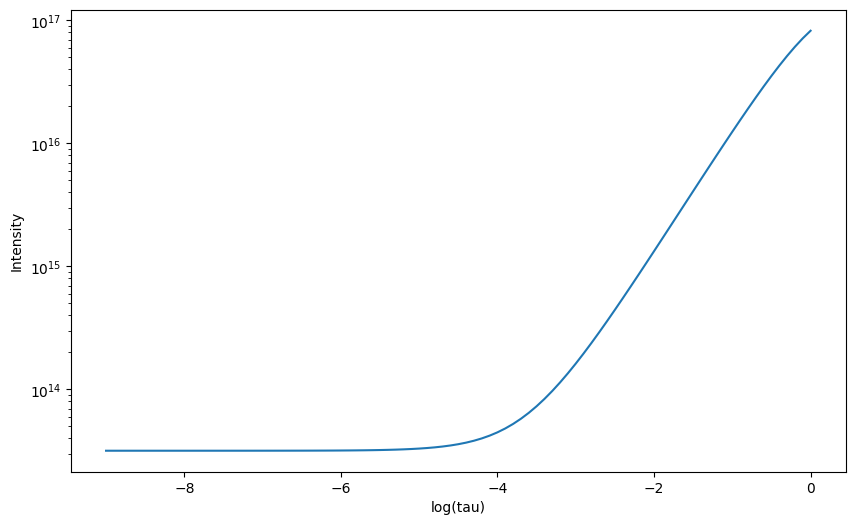

In [14]:
# Nista, sada lepo isplotujemo ovo:
plt.figure(figsize=[10, 6])
plt.semilogy(logtau, I_k)
#plt.hlines(I_f, logtau[0], logtau[-1], colors='r', linestyles='dashed')
plt.xlabel('log(tau)')
plt.ylabel('Intensity')


In [15]:
# Sve isto samo za lambda = 10 nm
I_f = Planck(T_f, lambda_2)
S_k = Planck(T_k, lambda_2)
I_k = resi_jpz(I_f, tau, S_k)

Text(0, 0.5, 'Intensity')

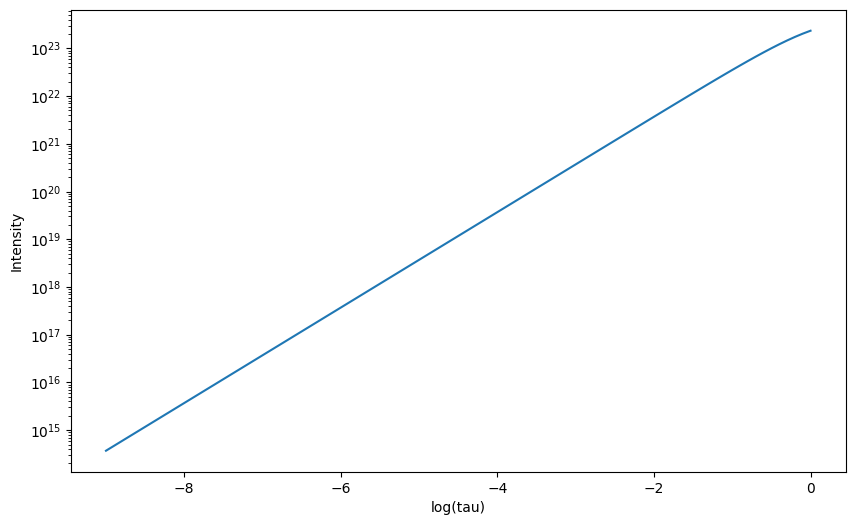

In [16]:
# Nista, sada lepo isplotujemo ovo:
plt.figure(figsize=[10, 6])
plt.semilogy(logtau, I_k)
#plt.hlines(I_f, logtau[0], logtau[-1], colors='r', linestyles='dashed')
plt.xlabel('log(tau)')
plt.ylabel('Intensity')


In [17]:
# Wow, vec za ove male opticke dubine, ispada da je korona previse intenzivna i ne mozemo da vidimo prelaz izmedju toga 
# kada vidimo samo fotosferu i kada vidimo i koronu
# Hajde da razmotrimo drasticno manje opticke dubine
logtau = np.linspace(-18,-9,91)
tau = 10**logtau

In [18]:
# Sve isto samo za lambda = 10 nm
I_f = Planck(T_f, lambda_2)
S_k = Planck(T_k, lambda_2)
I_k = resi_jpz(I_f, tau, S_k)

In [21]:
# Da proverimo, koliki je intenzitet fotosfere na ovoj talasnoj duzini? 
# I kolika je funkcija izvora u koroni?
print(I_f)
print(S_k)

8.585870477535851e-81
3.704025613720854e+23


Text(0, 0.5, 'Intensity')

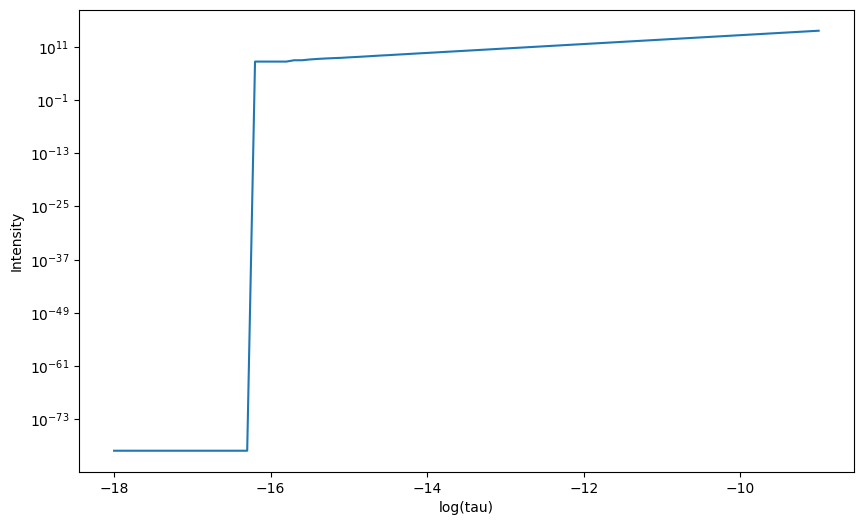

In [19]:
# Nista, sada lepo isplotujemo ovo:
plt.figure(figsize=[10, 6])
plt.semilogy(logtau, I_k)
#plt.hlines(I_f, logtau[0], logtau[-1], colors='r', linestyles='dashed')
plt.xlabel('log(tau)')
plt.ylabel('Intensity')


In [22]:
# Brojevi su TOLIKO mali da je NA OVOJ TALASNOJ DUZIN intenzitet fotosfera zanemarljiv u odnosu 
# na koronu za maltene bilo koju vrednost opticke dubine.